In [1]:
!pip install pandas numpy matplotlib wordcloud

Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
# Step 1: Required libraries import karein
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("niraliivaghani/flipkart-product-customer-reviews-dataset")

print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

Dataset shape (rows, columns): (205052, 6)
Available columns: ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']
Cleaned rows count: 205049

Summary DataFrame ('items') preview:


,product_name,mean_rating,mean_price,review_count
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0,150
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0,376
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0,9
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0,100
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0,28
5,77085PP03 Volt Analog Watch For Men,4.71,699.0,45
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0,16
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0,56
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0,62
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0,200


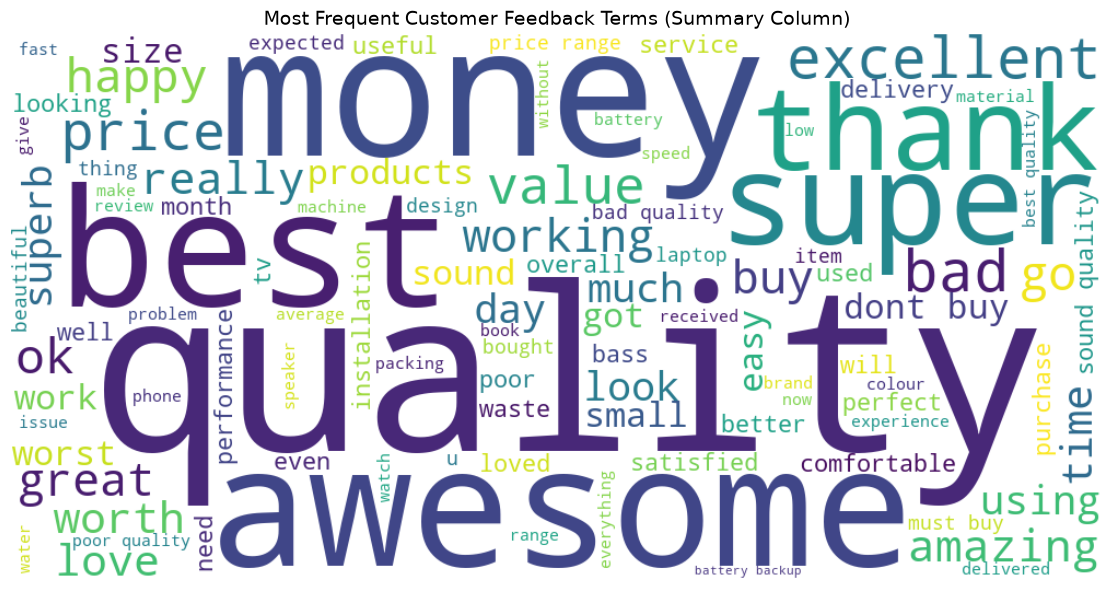

In [4]:
# Step 2: Dataset load karein
csv_path = "flipkart_product_reviews.csv"  # Apni CSV file ka exact naam likhein
df = pd.read_csv(csv_path)

print("Dataset shape (rows, columns):", df.shape)
print("Available columns:", df.columns.tolist())

# Agar aapke dataset mein column names alag hain to yahan update karein:
product_col = "product_name"   # e.g., "product_name" ya "Product_Name"
rating_col = "Rate"            # e.g., "Rating" ya "rating"
price_col = "product_price"            # e.g., "price" ya "Selling Price"
summary_col = "Summary"        # e.g., "Review" ya "summary"

# Step 3: Rating aur Price fields ki data cleaning
# 3a. Price cleaning: ₹, commas, aur extra text/spaces hata kar float mein badlein
df[price_col] = (
    df[price_col]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
    .replace("", np.nan)
)
df[price_col] = pd.to_numeric(df[price_col], errors="coerce")

# 3b. Rating cleaning: numeric mein badlein aur 0 se 5 ke valid range tak rakhein
df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")
df.loc[(df[rating_col] < 0) | (df[rating_col] > 5), rating_col] = np.nan

# Product name strip karein aur un rows ko hatayein jahan product, rating ya price missing ho
df[product_col] = df[product_col].astype(str).str.strip()
df.loc[df[product_col].isin(["", "nan", "None"]), product_col] = np.nan

cleaned_df = df.dropna(subset=[product_col, rating_col, price_col]).copy()
print("Cleaned rows count:", len(cleaned_df))

# Step 4: Product name ke hisaab se group karke mean rating aur mean price nikaalein
items = (
    cleaned_df.groupby(product_col, as_index=False)
    .agg(
        mean_rating=(rating_col, "mean"),
        mean_price=(price_col, "mean"),
        review_count=(rating_col, "count")
    )
)

# Values ko neatly round karein (optional)
items["mean_rating"] = items["mean_rating"].round(2)
items["mean_price"] = items["mean_price"].round(2)

print("\nSummary DataFrame ('items') preview:")
display(items.head(10))

# Optional: 'items' DataFrame ko CSV mein save karna ho to
items.to_csv("product_summary_items.csv", index=False)

# Step 5: 'Summary' column se Word Cloud generate aur display karein
if summary_col in df.columns:
    text_data = " ".join(df[summary_col].dropna().astype(str))

    if text_data.strip():
        custom_stopwords = set(STOPWORDS)
        custom_stopwords.update(["product", "flipkart", "good", "nice", "one", "use"])

        wordcloud = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            stopwords=custom_stopwords,
            max_words=100,
            colormap="viridis"
        ).generate(text_data)

        plt.figure(figsize=(14, 6))
        plt.imshow(wordcloud, interpolation="bilinear")
        plt.axis("off")
        plt.title("Most Frequent Customer Feedback Terms (Summary Column)", fontsize=14)
        plt.tight_layout()
        plt.show()
    else:
        print(f"'{summary_col}' column mein koi text data nahi mila.")
else:
    print(f"Warning: '{summary_col}' column dataset mein nahi mila. Available columns: {df.columns.tolist()}")